In [1]:
import jax
import os

jax.config.update('jax_platform_name', 'cpu')

# # Avoid OOM errors
# os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".33"
# # os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
print(f"JAX backend: {jax.default_backend()}")

JAX backend: cpu


In [2]:
import sys
sys.path.append("../")

# %load_ext autoreload
# %autoreload 2

import pulse_simulator as ps

/Users/andy/Documents/Research/Code.nosync/pulse-simulator/.venv/lib/python3.12/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Load pulses

In [5]:
# Calibrate the default X gates
default_gates = {}
for k in ["X1", "SX1", "I1", "X2", "SX2", "I2"]:
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    elif "X" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)
    elif "I" in k:
        default_gates[k] = ps.zero_envelope(duration_1qb)
    else:
        raise ValueError(f"Unknown gate {k}")
default_gates["I2"] = ps.zero_envelope(duration_1qb)


# Build circuit

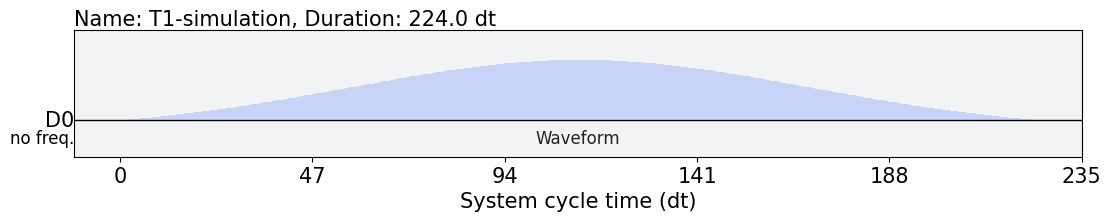

In [6]:
registers = [0]

my_moments = [{0: "X1"}]

my_schedule = ps.build_pulse_schedule(
    my_moments,
    default_gates,
    _,
    registers,
    backend,
    dt=dt,
    name="T1-simulation",
)

my_schedule.draw()

# Build model

In [21]:
# Set registers above with circuit
# The rest is automatic
# ===================== 

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        t1 = 250 / μs * ns
        cvars[k] = t1
    if "t2" in k:
        cvars[k] = None # 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

edges = ps.backend_edges(backend) #[1:-1]
print(f"Edges: {[e for e in edges if e[0] in registers and e[1] in registers]}")
H_xtalk = ps.crosstalk_model(registers, edges, cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # # Two qubit with ring connectivity
    # if qubit < len(registers) - 1:
    #     control, target = qubit, qubit + 1
        
    #     # Get both directions
    #     for pair in [(control, target), (target, control)]:
    #         Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
    #         H_drift += Hj_drift
    #         Hs_control += Hjs_control
    #         Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

Edges: []


In [23]:
solver = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

In [24]:
# y0 = ps.qiskit_identity_operator(len(registers))
y0 = ps.qiskit_ground_state(len(registers), open=True)

t_eval = np.linspace(my_schedule.duration * dt, 250 / μs * ns, 100)
t_wait = np.linspace(0, 250 / μs * ns, 100)
a_wait = np.zeros_like(t_wait)

solver.model.evaluation_mode = "dense"
res = solver.solve(
    t_span=[0.0, t_eval[-1]],
    t_eval=t_eval,
    y0=y0,
    signals=my_schedule,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

target = qk.quantum_info.DensityMatrix([[0, 0], [0, 1]])
fids = [ps.quantum_info.state_fidelity(y, target) for y in res.y]

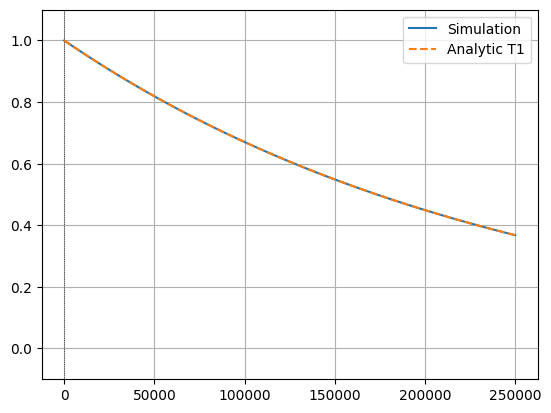

In [25]:
fig, ax = plt.subplots()
ax.plot(t_eval, fids, label="Simulation")

ax.axvline(my_schedule.duration * dt, lw=0.5, color="k", linestyle=":")

ax.plot(my_schedule.duration * dt + t_wait, np.exp(-t_wait / t1), ls="--", label="Analytic T1")

ax.legend()
ax.set_ylim(-0.1, 1.1)
ax.grid(True)

In [26]:
H_qutip =  [
    qt.Qobj(H_drift.data),
    [qt.Qobj(Hs_control[0].data), a_wait]
]

rho0 = qt.Qobj([[0, 0], [0, 1]])

# The factor of sqrt(2) would lead to correct T1 match... what's going on?
res_qt = qt.mesolve(
    H=H_qutip,
    rho0=rho0,
    tlist=t_wait,
    # c_ops=[np.sqrt(2)*qt.Qobj(A.data) for A in As_static]
    c_ops=[qt.Qobj(A.data) for A in As_static]
)

rhof = qt.Qobj([[0, 0], [0, 1]])
fids_qt = [qt.fidelity(s, rhof) for s in res_qt.states]

In [27]:
# The operator we're using to the get T1 is the one we'd expect
qt.destroy(2) / np.sqrt(t1) == qt.Qobj(As_static[0].data) 

True

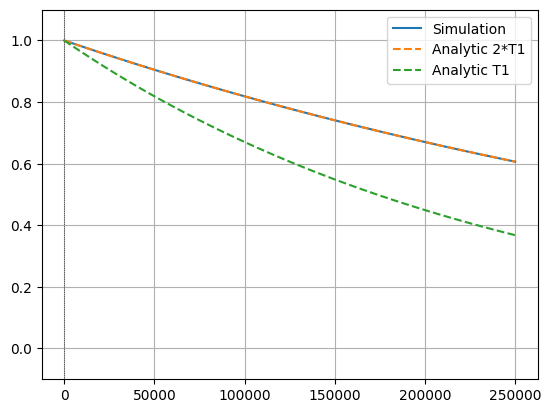

In [28]:
fig, ax = plt.subplots()

ax.plot(my_schedule.duration * dt + t_wait, fids_qt, label="Simulation")
ax.axvline(my_schedule.duration * dt, lw=0.5, color="k", linestyle=":")

# Qutip gets a factor of 1/2 in there. Why?
ax.plot(my_schedule.duration * dt + t_wait, np.exp(-t_wait / 2 / t1), ls="--", label="Analytic 2*T1")
ax.plot(my_schedule.duration * dt + t_wait, np.exp(-t_wait / t1), ls="--", label="Analytic T1")


ax.legend()

ax.set_ylim(-0.1, 1.1)
ax.grid(True)

In [14]:
from qutip.qip.device import Processor
from qutip.qip.pulse import Pulse

In [18]:
a = qt.destroy(2)
initial_state = qt.basis(2,1)

processor = Processor(1, t1=t1)
# creat a dummpy pulse that has no Hamiltonian, but only a tlist.
processor.add_pulse(Pulse(None, None, tlist=t_wait, coeff=False))
result = processor.run_state(init_state=initial_state, e_ops=[a.dag()*a])

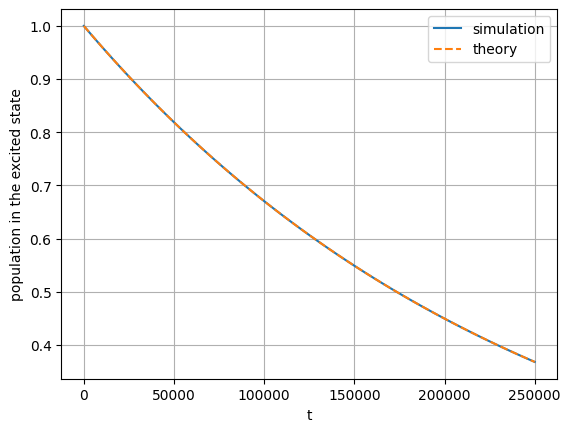

In [20]:
fig, ax = plt.subplots()
ax.plot(t_wait, result.expect[0], label="simulation")
ax.plot(t_wait, np.exp(-t_wait/t1), ls='--', label="theory")
ax.set_xlabel("t")
ax.set_ylabel("population in the excited state")
ax.legend()
plt.grid()